In [1]:
from visualize import Embedding

# baseline ro_en
baseline = Embedding(
        name="baseline (ro-en)",
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/',
        features_path='train.features.npy',
        targets_path='410.train.targets.npy',
        yaml_path="410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096_metadata.yaml",
        faiss_path='410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096'
    )
# dispersion ro_en
dispersion = Embedding(
        name="dispersion (ro-en)",
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion/',
        features_path='582.train.features.npy',
        targets_path='582.train.targets.npy',
        yaml_path="582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml",
        faiss_path='582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_512_4096'
    )
baseline.load()
dispersion.load()

/home/stroshi/miniconda3/envs/evgeniia/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, nclusters=4096, nprobe=32, ntotal=21507934)
Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, features_model='/ivi/ilps/personal/etokarc/models/translation/00582_ro_en_transformer_dispersion_ft/checkpoint_best.pt', nclusters=2048, nprobe=32, ntotal=21507934)


## Plans
-  cluster entropy (as a discrete histogram of points per center) and (related) average and median cluster size
-  total kmeans energy sum_i d^2 (x_i, q(x_i))
-  per-cluster energy for cluster z = sum_{x : q(x)=z} d^2(x, z)}
-  For every point, what % of its k nearest neighbors lie in the same cluster as the point (fix k to be what is used in decoding)
-  clustering evaluation metrics from sklearn (eg v -measure etc, using the token labels ("values" in the kv store) as labels (edited) 

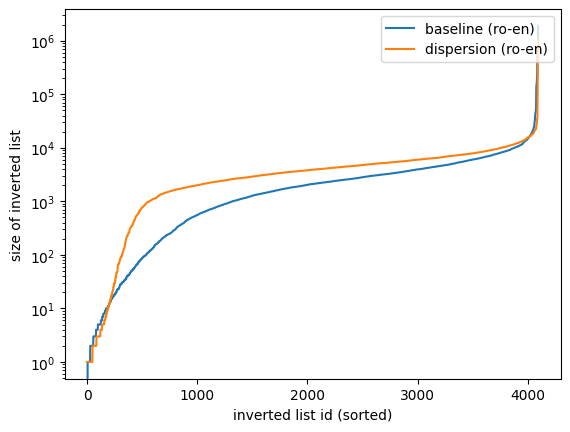

baseline (ro-en)
          mean  median
0  5250.960449  2109.0

dispersion (ro-en)
          mean  median
0  5250.960449  3894.5


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp

from typing import List, Tuple

def cluster_entropy(embedding: Embedding):
    """
    Returns: IVF cluster sizes
    """
    knn_index = embedding.knn_index
    sizes = []
    # print(knn_index.invlists.code_size)
    # print(knn_index.invlists.nlist)
    for i in range(knn_index.invlists.nlist):
        sizes.append(knn_index.invlists.list_size(i))
    return sizes

def make_sizes_plot(baseline: Embedding, dispersion: Embedding):
    """
    Plot the sizes of the IVF clusters for the baseline and dispersion embeddings.
    default: sorted mode by the size of the inverted list
    """
    sizes_baseline = cluster_entropy(baseline)
    sizes_dispersion = cluster_entropy(dispersion)
    sizes_baseline = np.sort(sizes_baseline)
    sizes_dispersion = np.sort(sizes_dispersion)

    fig, ax = plt.subplots()
    plt.plot(sizes_baseline, label=baseline.name)
    plt.plot(sizes_dispersion, label=dispersion.name)
    ax.legend(loc='upper right')
    ax.set_ylabel('size of inverted list')
    ax.set_xlabel('inverted list id (sorted)')
    # log scale
    ax.set_yscale('log')
    plt.show()


def make_mean_median_cluster_sizes(embedding) -> pd.DataFrame:
    sizes = cluster_entropy(embedding)
    sizes = np.array(sizes)
    mean = np.mean(sizes)
    median = np.median(sizes)
    df = pd.DataFrame({'mean': [mean], 'median': [median]})
    return df


########### script. ##########

make_sizes_plot(baseline, dispersion)

# make mean and median cluster sizes
df_baseline = make_mean_median_cluster_sizes(baseline)
df_dispersion = make_mean_median_cluster_sizes(dispersion)

print(baseline.name)
print(df_baseline)
print()
print(dispersion.name)
print(df_dispersion)


- why mean is *exactly* the same for baseline and dispersion?
- dispersion makes clusters more equal in size

Baseline total kmeans energy: 2305178.5 +- 9513.938178116949
Dispersion total kmeans energy: 1989874.0 +- 12606.977461065426


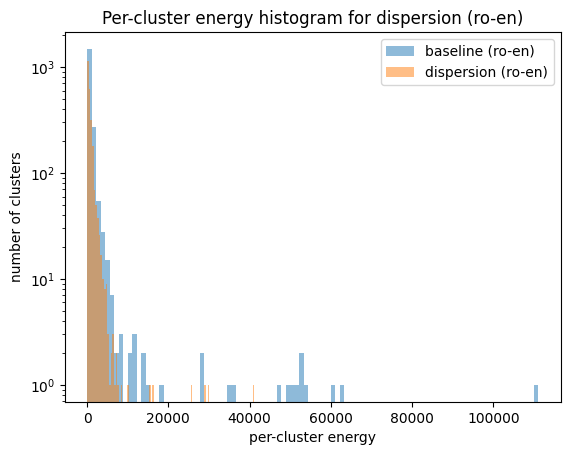

In [3]:



def sample_d_i_ivf_kmeans(embedding, n_crop=1000000, n_sample=10000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature)
    keys = embedding.keys[:n_crop]  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    D, I = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    return D.flatten(), I.flatten()


def total_kmeans_energy(embedding) -> Tuple[float, float]:
    """
    Returns:
    total kmeans energy sum_i d^2 (x_i, q(x_i))
    lower and upper confidence intervals
    """
    # total kmeans energy with std
    energies = []
    for seed in range(5):
        dss, _ = sample_d_i_ivf_kmeans(embedding, n_crop=1000000, n_sample=10000, seed=seed)
        energy = np.sum(dss)
        energies.append(energy)
    # calculate mean and std
    # for the energies
    mean = np.mean(energies)
    std = sp.stats.sem(energies)
    return mean, std


def per_cluster_energy(embedding) -> List[float]:
    #  per-cluster energy for cluster z = sum_{x : q(x)=z} d^2(x, z)}
    dss, ids = sample_d_i_ivf_kmeans(embedding, n_crop=1000000, n_sample=10000)
    energies = []
    for id in np.sort(np.unique(ids)):
        indices_with_id = np.where(ids == id)[0]
        dss_for_id = dss[indices_with_id]
        energies.append(dss_for_id.sum())
    return energies


print("Baseline total kmeans energy: {} +- {}".format(*total_kmeans_energy(baseline)))
print("Dispersion total kmeans energy: {} +- {}".format(*total_kmeans_energy(dispersion)))


# make a histogram of the per-cluster energy
def make_per_cluster_energy_histogram(energies, embedding, ax):
    ax.hist(energies, bins=100, label=embedding.name, alpha=0.5)
    ax.set_xlabel('per-cluster energy')
    ax.set_ylabel('number of clusters')
    ax.set_title(f'Per-cluster energy histogram for {embedding.name}')
    ax.set_yscale('log')

fig, ax = plt.subplots()
make_per_cluster_energy_histogram(
    per_cluster_energy(baseline),
    baseline, ax
)
make_per_cluster_energy_histogram(
    per_cluster_energy(dispersion),
    dispersion, ax
)
ax.legend()
plt.show()


- for dispersion it seems that the energy is lower. stds over 5 seeds to not intersect (check that I do it correctly!) - (2305178.5 - 19027.875), (1989874.0 + 25213.955078125) = (2286150.625, 2015087.955078125)
- Currently to speed up things I crop first N points to speed up reading from the disk, but should sample from all points for the final run?

Mean same cluster: 99.6 +- 0.2825591608118863
Mean same cluster: 92.0 +- 0.8446459931281357
Mean same cluster: 87.5 +- 1.083904838719155
Mean same cluster: 84.75 +- 1.192778454232706
Mean same cluster: 83.25 +- 1.2451559447126719
Mean same cluster: 96.8 +- 0.7878842066230876
Mean same cluster: 92.2 +- 0.9900911882863339
Mean same cluster: 89.6 +- 1.1230326819864231
Mean same cluster: 88.05 +- 1.183616024641258
Mean same cluster: 86.4125 +- 1.2481111731336283


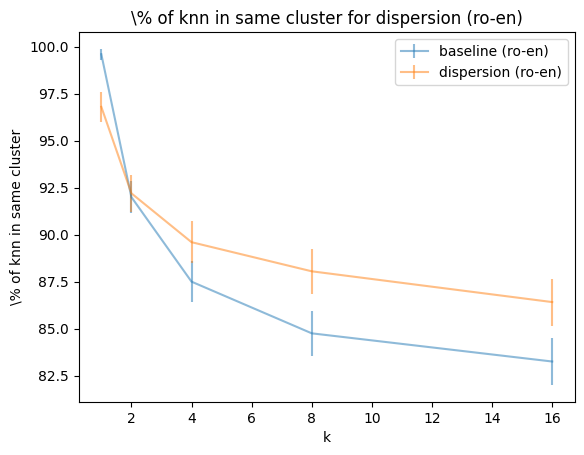

In [4]:


def extract_k_neighbors(embedding, k_neignbors=8, n_crop=100000, n_sample=1000, seed=0) -> Tuple[np.ndarray, np.ndarray]:
    """Return:
    List of (D, I) for sampled vector in the dataset
    Ds are squeared distances to the cluster centers
    Is are the cluster ids
    """
    # save values and corresponding cluster_id(feature) 
    keys = embedding.keys[:n_crop]  # use more for final plot
    np.random.seed(seed)
    indices = np.random.choice(len(keys), n_sample, replace=False)
    keys = keys[indices]
    D, I = embedding.knn_index.search(keys, k=k_neignbors) # (n_first, 1), (n_first, 1)
    assert D.shape == (n_sample, k_neignbors)
    assert I.shape == (n_sample, k_neignbors)
    return keys, D, I


def same_knn_cluster(embedding, k_neignbors=8, n_crop=100000, n_sample=1000, seed=0) -> np.ndarray:
    # For every point, what % of its k nearest neighbors lie in the same cluster as the point (fix k to be what is used in decoding)
    # extract k neighbors and their cluster ids
    keys, knn_d, knn_i = extract_k_neighbors(embedding, k_neignbors=k_neignbors, n_crop=n_crop, n_sample=n_sample, seed=seed)
    cluster_d, cluster_i = embedding.knn_index.quantizer.search(keys, k=1) # (n_first, 1), (n_first, 1)
    
    # get embeddings of knns
    knn_keys = embedding.keys[knn_i]
    flat_knn_keys = knn_keys.reshape(-1, knn_keys.shape[-1])

    knn_cluster_d, knn_cluster_i = embedding.knn_index.quantizer.search(flat_knn_keys, k=1) # (n_first, 1), (n_first, 1)
    knn_cluster_d = knn_cluster_d.reshape(knn_i.shape)
    knn_cluster_i = knn_cluster_i.reshape(knn_i.shape)

    # compare cluster_i vs knn_cluster_i
    matched_clusters = knn_cluster_i == cluster_i
    # calculate the percentage of knn that are in the same cluster
    same_cluster = np.sum(matched_clusters, axis=1) / k_neignbors * 100
    # calculate the mean and std
    mean = np.mean(same_cluster)
    std = sp.stats.sem(same_cluster)
    print("Mean same cluster: {} +- {}".format(mean, std))
    return (mean, std)


def plot_same_knn_cluster(ax, embedding, n_crop=100000, n_sample=1000, seed=0, nprobe=32):
    original_nprobe = embedding.knn_index.nprobe
    embedding.knn_index.nprobe = nprobe
    try:
        # extract k
        means = []
        stds = []
        ks = []
        for k in (1, 2, 4, 8, 16):
            (mean, std) = same_knn_cluster(embedding, k_neignbors=k, n_crop=n_crop, n_sample=n_sample, seed=seed)
            means.append(mean)
            stds.append(std)
            ks.append(k)
        # plot the means and stds
        ax.errorbar(ks, means, yerr=stds, label=embedding.name, alpha=0.5)
        ax.set_xlabel('k')
        ax.set_ylabel(f'\% of knn in same cluster')
        ax.set_title(f'\% of knn in same cluster for {embedding.name}')
        ax.legend()
    finally:
        # reset nprobe
        embedding.knn_index.nprobe = original_nprobe

    assert embedding.knn_index.nprobe == original_nprobe

fig, ax = plt.subplots()
plot_same_knn_cluster(ax, baseline, n_crop=1000000, n_sample=500, seed=0, nprobe=32)
plot_same_knn_cluster(ax, dispersion, n_crop=1000000, n_sample=500, seed=0, nprobe=32)
plt.show()


It looks like there is no difference in the persentage of the nearest neigbors to be in the same cluster.

In [ ]:
baseline.knn_index.nprobe

32